In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('../')
print(sys.path)

['/home/thule/miniconda3/envs/open-clip-training/lib/python311.zip', '/home/thule/miniconda3/envs/open-clip-training/lib/python3.11', '/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/lib-dynload', '', '/home/thule/miniconda3/envs/open-clip-training/lib/python3.11/site-packages', '../']


In [7]:
classes = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
n_classes = len(classes)

In [5]:
confusion_matrix = np.array(
[[20828,    5,    0,    21,    38,     7,    14,    30,    18,    12],
 [   92,  1223,     0,     0,     0,     0,     0,     0,     0,     0],
 [   17,     0,   184,     0,     0,     0,     0,     0,     0,     0],
 [   22,     1,     0,   229,     0,     0,     0,     1,     0,     1],
 [   40,     0,     0,     0,   172,     0,     0,     0,     0,     0],
 [  130,     0,     0,     3,     1,  1772,     0,     1,     2,     0],
 [   62,     0,     0,     0,     0,     0,   334,     2,     0,     1],
 [   33,     0,     0,     0,     0,     0,     0,   446,     0,     0],
 [   10,     0,     0,     0,     0,     0,     0,     0,   176,     0],
 [   48,     0,     0,     0,     1,     0,     0,     0,     0,   238]]
)

In [17]:
def draw_confusion_matrix(cm, classes, save_dir=None):
    cm_df = pd.DataFrame(cm,
                     index = classes, 
                     columns = classes)
    mask = np.zeros_like(cm)
    np.fill_diagonal(mask, 1)
    plt.figure(figsize=(10,8))
    # sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, linewidths=0.5)
    sns.heatmap(cm_df, fmt='d', annot=True, cmap='YlGnBu', cbar=False, 
            linewidths=0.5, vmin=0, vmax=2500,)
    plt.xticks(rotation=45, ha='right')
    plt.title('Confusion Matrix')
    plt.ylabel('Actual Values')
    plt.xlabel('Predicted Values')
    # if save_dir is not None:
    #     plt.savefig(save_dir.format(ckpt_epoch), dpi=300, bbox_inches="tight", pad_inches=0.5)
    plt.show()

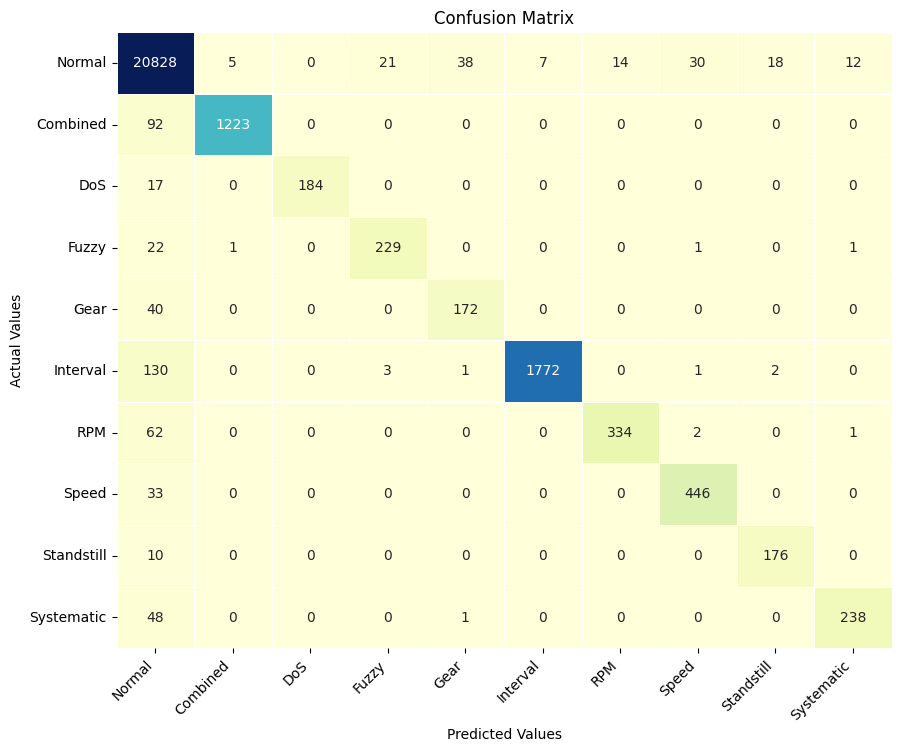

In [18]:
draw_confusion_matrix(confusion_matrix, classes)

In [12]:
from vit_pytorch.vit import ViT
import torch

def change_state_dict(state_dict):
    """
    Because state dict in distributed GPU is different
    """
    new_state_dict = {}
    for k, v in state_dict.items():
        k = k.replace("module.", "")
        new_state_dict[k] = v
    return new_state_dict

model = ViT(
        dim = 128,
        num_classes = 10,
        image_size = 64,
        patch_size = 4,
        depth = 6,
        heads = 8,
        dim_head = 64,
        mlp_dim = 128 * 4,
        # decorr_sample_frac = 1. # use all tokens
    )

save_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_ViT_lr_0.03_decay_0.0001_bsz_64_trial_0/051426_025959'
# save_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_rec_cnn_lr_0.05_decay_0.0001_bsz_128_trial_can_ml_rec_cnn_64_cosine_warm' # 10% data, LSTM 
# save_path = '../save/CAN-ML_models/BaseLine/BaseLine_CAN-ML_rec_cnn_lr_0.05_decay_0.0001_bsz_128_trial_can_ml_rec_cnn_64_cosine_warm' # 10% data, RecCNN
ckpt_epoch = 50

model_path = f'{save_path}/ckpt_epoch_{ckpt_epoch}.pth'
ckpt = torch.load(model_path, weights_only=False)
state_dict = ckpt['model']
state_dict = change_state_dict(state_dict)
model.load_state_dict(state_dict=state_dict, strict=False)

<All keys matched successfully>

In [14]:
from dataset import CANDatasetEnet as CANDataset

test_dataset = CANDataset(root_dir='../data/size_64_10/TFRecord_w64_s32/2/', window_size=32, is_train=False, include_data=False)

test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

In [15]:
import numpy as np
import tqdm
import torch
from sklearn.metrics import accuracy_score, classification_report

total_pred = np.empty(shape=(0), dtype=int)
total_label = np.empty(shape=(0), dtype=int)

device = torch.device("cuda")
model = model.to(device)
model.eval()

with torch.no_grad():
    for images, labels in tqdm.tqdm(test_loader):
        images = images.to(device, non_blocking=True)
        
        outputs = model(images)
        
        _, pred = torch.max(outputs, 1)
        
        pred = pred.cpu().numpy()
        labels = labels.cpu().numpy()
        
        total_pred = np.concatenate((total_pred, pred), axis=0)
        total_label = np.concatenate((total_label, labels), axis=0)

100%|██████████| 410/410 [00:18<00:00, 21.88it/s]


In [16]:
accuracy = accuracy_score(total_label, total_pred) 
print("Accuracy:", accuracy)

target_names = ['Normal', 'Combined', 'DoS', 'Fuzzy', 'Gear', 'Interval', 'RPM', 'Speed', 'Standstill', 'Systematic']
report = classification_report(total_label, total_pred, target_names=target_names, digits=4)
print("Classification Report:\n", report)

Accuracy: 0.976616440968911
Classification Report:
               precision    recall  f1-score   support

      Normal     0.9787    0.9931    0.9858     20973
    Combined     0.9951    0.9300    0.9615      1315
         DoS     1.0000    0.9154    0.9558       201
       Fuzzy     0.9051    0.9016    0.9034       254
        Gear     0.8113    0.8113    0.8113       212
    Interval     0.9961    0.9282    0.9610      1909
         RPM     0.9598    0.8371    0.8942       399
       Speed     0.9292    0.9311    0.9301       479
  Standstill     0.8980    0.9462    0.9215       186
  Systematic     0.9444    0.8293    0.8831       287

    accuracy                         0.9766     26215
   macro avg     0.9418    0.9023    0.9208     26215
weighted avg     0.9767    0.9766    0.9764     26215



### Visualize training loss and validation loss curve

In [6]:
import os
from matplotlib.ticker import MaxNLocator


def plot_loss_curves(train_losses, val_losses, save_folder):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt

    epochs = range(1, len(train_losses) + 1)
    save_file = os.path.join(save_folder, 'loss_curve.png')

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_losses, label='Training loss')
    plt.plot(epochs, val_losses, label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(save_file, dpi=200)
    plt.close()

In [ ]:
train_losses = [0.8, 0.6, 0.4, 0.3, 0.25]
val_losses = [0.9, 0.7, 0.5, 0.35, 0.3]

In [ ]:
plot_loss_curves(train_losses, val_losses)